# Track 01 Workflow Notebook - Placental Guidance


This notebook follows the [analysis workflow](../3-workflow.md) step by step. Each numbered section matches a step in that guide, so read them side by side.

The notebook handles the coding. Your team makes the decisions. Cells you need to edit are marked **You decide**. Everything else runs as is.

Run cells from top to bottom with Shift+Enter.

## 0. Setup

Works on your own computer and on Google Colab. On Colab this cell downloads the repository and installs PyDESeq2, which takes about a minute.

In [ ]:
import os, sys, subprocess
from pathlib import Path

if "google.colab" in sys.modules:
    if not Path("/content/openbio-datathon-2026").exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/Harvard-Undergraduate-OpenBio/openbio-datathon-2026.git", "/content/openbio-datathon-2026"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pydeseq2"], check=True)
    os.chdir("/content/openbio-datathon-2026/track-01/notebooks")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

DATA_DIR = Path("../data")
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
print("Setup complete. Data folder:", DATA_DIR.resolve())


Setup complete. Data folder: /content/openbio-datathon-2026/track-01/data


## 1. Pick a Question

Choose one from the [starter questions](../starter-questions.md) and write it here. Double-click this cell to edit it.

**You decide:** Our question is question 6, how much of the difference between preeclampsia and control samples could be explained by when delivery happened?

## 2. Load and Check the Data

Loads the count table (genes by samples) and the metadata table (one row per sample), then checks that they fit together. If a check prints `False` or a nonzero duplicate count, note it in your analysis plan and tell an organizer. Do not edit the data files.

In [ ]:
def load_table(path):
    if not path.exists() or path.stat().st_size == 0:
        print(f"{path.name}: pending release (file is empty for now).")
        return None
    return pd.read_csv(path, index_col=0)

counts = load_table(DATA_DIR / "track01_counts_vt.csv")
metadata = load_table(DATA_DIR / "track01_metadata_vt.csv")

if counts is not None and metadata is not None:
    print(f"Counts: {counts.shape[0]:,} genes x {counts.shape[1]} samples")
    print(f"Metadata: {metadata.shape[0]} samples x {metadata.shape[1]} fields")
    print()
    print("Samples in both tables:      ", len(set(counts.columns) & set(metadata.index)))
    print("Counts are nonnegative:      ", bool((counts.values >= 0).all()))
    print("Counts are whole numbers:    ", bool((counts.values % 1 == 0).all()))
    print("Duplicate genes:             ", int(counts.index.duplicated().sum()))
    print("Duplicate samples:           ", int(counts.columns.duplicated().sum()))
    # Put metadata rows in the same order as the count columns
    metadata = metadata.loc[counts.columns]

Counts: 26,485 genes x 30 samples
Metadata: 30 samples x 20 fields

Samples in both tables:       30
Counts are nonnegative:       True
Counts are whole numbers:     True
Duplicate genes:              0
Duplicate samples:            0


Look at the metadata fields and how many values are missing in each. The [data dictionary](../data/track01_data_dictionary.md) explains every column.

In [ ]:
if metadata is not None:
    overview = pd.DataFrame({
        "example_value": metadata.iloc[0],
        "n_missing": metadata.isna().sum(),
        "n_unique": metadata.nunique(),
    })
    display(overview)

,example_value,n_missing,n_unique
geo_accession,GSM6175116,0,30
donor_id,S01,0,30
group,EOPE+FGR,0,5
pe_status,PE,0,2
pe_onset,early_onset,0,2
fgr_status,FGR,0,2
control_type,not_control,0,3
ga_delivery_source,33.4,0,23
ga_delivery_completed_weeks,33,0,10
ga_delivery_extra_days,4,0,8


birthweight_interval_g =	5 missing
birthweight_lower_g	=	5 missing
birthweight_upper_g	=	5 missing


sbp_max_mmhg =	5	missing
dbp_max_mmhg =	5 missing


## 3. Explore the Samples

The PCA plot places samples with similar overall gene activity close together. Change `COLOR_BY` to different metadata columns and rerun the cell to see which fields line up with the main patterns.

Write what you notice in your analysis plan. This guides Step 4.

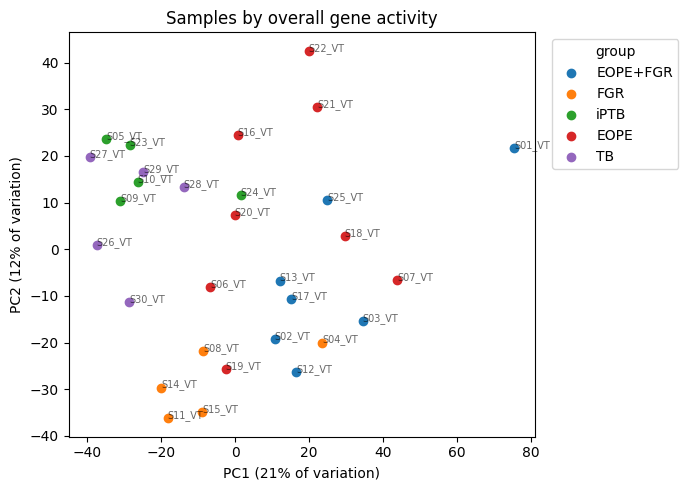

In [ ]:
# You decide: a metadata column name to color the points by
COLOR_BY = "group"

def plot_pca(counts, metadata, color_by=None):
    # Scale each sample to counts per million, then log transform so a few huge genes do not dominate
    log_cpm = np.log2(counts.div(counts.sum(axis=0), axis=1) * 1e6 + 1)
    pca = PCA(n_components=2)
    scores = pca.fit_transform(log_cpm.T)
    fig, ax = plt.subplots(figsize=(7, 5))
    if color_by is None:
        ax.scatter(scores[:, 0], scores[:, 1])
    else:
        values = metadata[color_by]
        if pd.api.types.is_numeric_dtype(values):
            points = ax.scatter(scores[:, 0], scores[:, 1], c=values, cmap="viridis")
            fig.colorbar(points, ax=ax, label=color_by)
        else:
            for level in values.fillna("NA").unique():
                mask = (values.fillna("NA") == level).values
                ax.scatter(scores[mask, 0], scores[mask, 1], label=str(level))
            ax.legend(title=color_by, bbox_to_anchor=(1.02, 1), loc="upper left")
    for i, sample in enumerate(counts.columns):
        ax.annotate(sample, scores[i], fontsize=7, alpha=0.6)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variation)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variation)")
    ax.set_title("Samples by overall gene activity")
    plt.tight_layout()
    plt.show()

if counts is not None:
    plot_pca(counts, metadata, COLOR_BY)

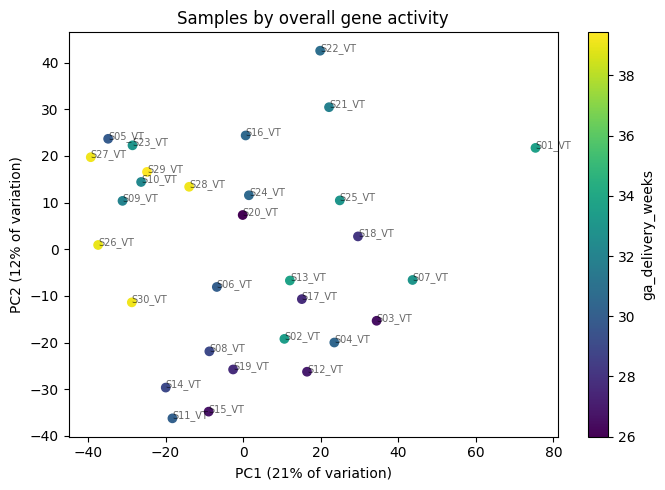

In [ ]:
# You decide: a metadata column name to color the points by
COLOR_BY = "ga_delivery_weeks"

def plot_pca(counts, metadata, color_by=None):
    # Scale each sample to counts per million, then log transform so a few huge genes do not dominate
    log_cpm = np.log2(counts.div(counts.sum(axis=0), axis=1) * 1e6 + 1)
    pca = PCA(n_components=2)
    scores = pca.fit_transform(log_cpm.T)
    fig, ax = plt.subplots(figsize=(7, 5))
    if color_by is None:
        ax.scatter(scores[:, 0], scores[:, 1])
    else:
        values = metadata[color_by]
        if pd.api.types.is_numeric_dtype(values):
            points = ax.scatter(scores[:, 0], scores[:, 1], c=values, cmap="viridis")
            fig.colorbar(points, ax=ax, label=color_by)
        else:
            for level in values.fillna("NA").unique():
                mask = (values.fillna("NA") == level).values
                ax.scatter(scores[mask, 0], scores[mask, 1], label=str(level))
            ax.legend(title=color_by, bbox_to_anchor=(1.02, 1), loc="upper left")
    for i, sample in enumerate(counts.columns):
        ax.annotate(sample, scores[i], fontsize=7, alpha=0.6)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variation)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variation)")
    ax.set_title("Samples by overall gene activity")
    plt.tight_layout()
    plt.show()

if counts is not None:
    plot_pca(counts, metadata, COLOR_BY)

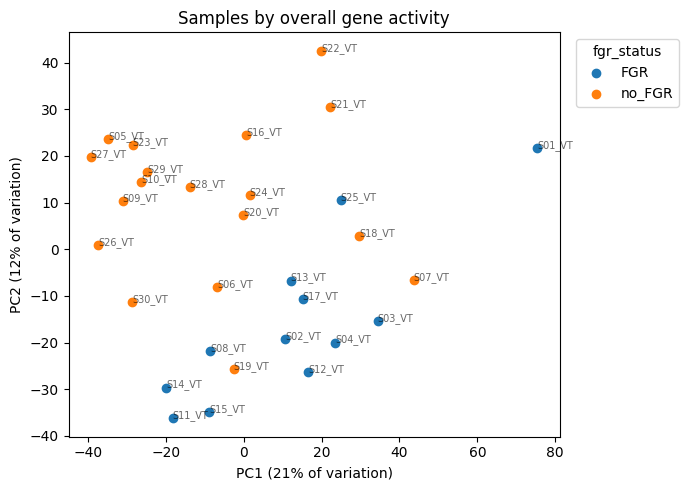

In [ ]:
# You decide: a metadata column name to color the points by
COLOR_BY = "fgr_status"

def plot_pca(counts, metadata, color_by=None):
    # Scale each sample to counts per million, then log transform so a few huge genes do not dominate
    log_cpm = np.log2(counts.div(counts.sum(axis=0), axis=1) * 1e6 + 1)
    pca = PCA(n_components=2)
    scores = pca.fit_transform(log_cpm.T)
    fig, ax = plt.subplots(figsize=(7, 5))
    if color_by is None:
        ax.scatter(scores[:, 0], scores[:, 1])
    else:
        values = metadata[color_by]
        if pd.api.types.is_numeric_dtype(values):
            points = ax.scatter(scores[:, 0], scores[:, 1], c=values, cmap="viridis")
            fig.colorbar(points, ax=ax, label=color_by)
        else:
            for level in values.fillna("NA").unique():
                mask = (values.fillna("NA") == level).values
                ax.scatter(scores[mask, 0], scores[mask, 1], label=str(level))
            ax.legend(title=color_by, bbox_to_anchor=(1.02, 1), loc="upper left")
    for i, sample in enumerate(counts.columns):
        ax.annotate(sample, scores[i], fontsize=7, alpha=0.6)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variation)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variation)")
    ax.set_title("Samples by overall gene activity")
    plt.tight_layout()
    plt.show()

if counts is not None:
    plot_pca(counts, metadata, COLOR_BY)

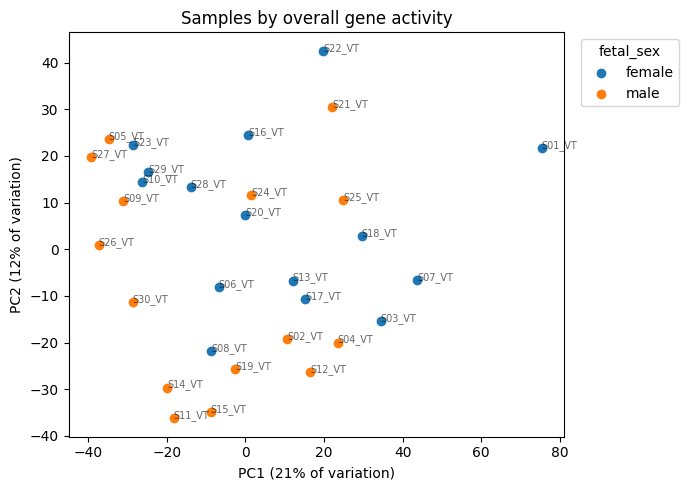

In [ ]:
# You decide: a metadata column name to color the points by
COLOR_BY = "fetal_sex"

def plot_pca(counts, metadata, color_by=None):
    # Scale each sample to counts per million, then log transform so a few huge genes do not dominate
    log_cpm = np.log2(counts.div(counts.sum(axis=0), axis=1) * 1e6 + 1)
    pca = PCA(n_components=2)
    scores = pca.fit_transform(log_cpm.T)
    fig, ax = plt.subplots(figsize=(7, 5))
    if color_by is None:
        ax.scatter(scores[:, 0], scores[:, 1])
    else:
        values = metadata[color_by]
        if pd.api.types.is_numeric_dtype(values):
            points = ax.scatter(scores[:, 0], scores[:, 1], c=values, cmap="viridis")
            fig.colorbar(points, ax=ax, label=color_by)
        else:
            for level in values.fillna("NA").unique():
                mask = (values.fillna("NA") == level).values
                ax.scatter(scores[mask, 0], scores[mask, 1], label=str(level))
            ax.legend(title=color_by, bbox_to_anchor=(1.02, 1), loc="upper left")
    for i, sample in enumerate(counts.columns):
        ax.annotate(sample, scores[i], fontsize=7, alpha=0.6)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variation)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variation)")
    ax.set_title("Samples by overall gene activity")
    plt.tight_layout()
    plt.show()

if counts is not None:
    plot_pca(counts, metadata, COLOR_BY)

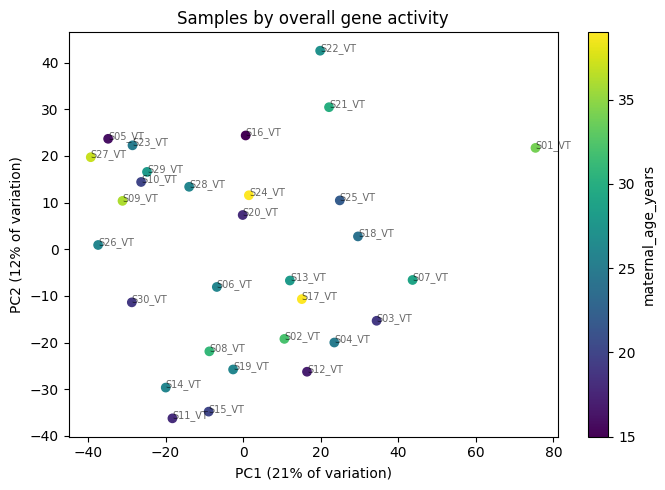

In [ ]:
# You decide: a metadata column name to color the points by
COLOR_BY = "maternal_age_years"

def plot_pca(counts, metadata, color_by=None):
    # Scale each sample to counts per million, then log transform so a few huge genes do not dominate
    log_cpm = np.log2(counts.div(counts.sum(axis=0), axis=1) * 1e6 + 1)
    pca = PCA(n_components=2)
    scores = pca.fit_transform(log_cpm.T)
    fig, ax = plt.subplots(figsize=(7, 5))
    if color_by is None:
        ax.scatter(scores[:, 0], scores[:, 1])
    else:
        values = metadata[color_by]
        if pd.api.types.is_numeric_dtype(values):
            points = ax.scatter(scores[:, 0], scores[:, 1], c=values, cmap="viridis")
            fig.colorbar(points, ax=ax, label=color_by)
        else:
            for level in values.fillna("NA").unique():
                mask = (values.fillna("NA") == level).values
                ax.scatter(scores[mask, 0], scores[mask, 1], label=str(level))
            ax.legend(title=color_by, bbox_to_anchor=(1.02, 1), loc="upper left")
    for i, sample in enumerate(counts.columns):
        ax.annotate(sample, scores[i], fontsize=7, alpha=0.6)
    ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variation)")
    ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variation)")
    ax.set_title("Samples by overall gene activity")
    plt.tight_layout()
    plt.show()

if counts is not None:
    plot_pca(counts, metadata, COLOR_BY)

## 4. Choose a Comparison

Define the two groups you will compare. Use exact column names and values from the metadata table (Section 2 lists them).

- `GROUP_COLUMN`: the column that defines your groups
- `CASE` and `CONTROL`: the two values of that column to compare
- `COVARIATES`: other columns to account for, such as gestational age. Leave as `[]` for none.

Write a short justification for these choices in your analysis plan.

In [ ]:
# STEP 4: BUILD COMPARISONS FOR ALL RUNS

# You decide
GROUP_COLUMN = "pe_status"
CASE = "PE"
CONTROL = "no_PE"

runs = {
    "A_naive": {
        "covariates": [],
        "rows": metadata["ga_delivery_weeks"] > 0,
        "title": "Run A: all weeks, no adjustment"
    },
    "B_adjusted": {
        "covariates": ["ga_delivery_weeks", "fetal_sex"],
        "rows": metadata["ga_delivery_weeks"] > 0,
        "title": "Run B: all weeks, adjusted for GA and sex"
    },
    #preterm:
    "C_ga34": {
        "covariates": ["ga_delivery_weeks", "fetal_sex"],
        "rows": (metadata["ga_delivery_weeks"] > 0) & (metadata["ga_delivery_weeks"] <= 34),
        "title": "Run C: 34 weeks or earlier, adjusted for GA and sex"
    },
}


def build_comparison(counts, metadata):
    if None in (GROUP_COLUMN, CASE, CONTROL):
        print("Fill in GROUP_COLUMN, CASE and CONTROL above, then rerun this cell.")
        return None, None

    used = [GROUP_COLUMN] + list(COVARIATES)
    meta = metadata[metadata[GROUP_COLUMN].isin([CASE, CONTROL])][used].copy()

    n_before = len(meta)
    meta = meta.dropna()

    if len(meta) < n_before:
        print(f"Note: {n_before - len(meta)} sample(s) dropped for missing values in {used}. Report this.")

    meta[GROUP_COLUMN] = meta[GROUP_COLUMN].astype(str)
    print(meta[GROUP_COLUMN].value_counts().to_string())

    return counts.loc[:, meta.index], meta


# Build each comparison
comparisons = {}

for name, run in runs.items():
    print("\n=====", name, "=====")

    COVARIATES = run["covariates"]

    comp_counts, comp_meta = (None, None) if counts is None else build_comparison(
        counts,
        metadata.loc[run["rows"]]
    )

    comparisons[name] = {
        "counts": comp_counts,
        "metadata": comp_meta,
        "covariates": COVARIATES,
        "title": run["title"]
    }

    if comp_meta is not None:
        print(f"Samples retained: {len(comp_meta)}")


===== A_naive =====
pe_status
PE       15
no_PE    15
Samples retained: 30

===== B_adjusted =====
pe_status
PE       15
no_PE    15
Samples retained: 30

===== C_ga34 =====
pe_status
PE       15
no_PE    10
Samples retained: 25


##5. Run the Test
Runs differential expression with PyDESeq2. It adjusts for sequencing depth, then tests every gene for a difference between `CASE` and `CONTROL` that is larger than the natural variation between samples. Expect a few seconds to a few minutes.

In [ ]:
# STEP 5: RUN DESEQ2 FOR ALL COMPARISONS

from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

all_runs = {}

for name, run in comparisons.items():
    print("\n=====", name, "=====")

    comp_counts = run["counts"]
    comp_meta = run["metadata"]
    COVARIATES = run["covariates"]

    results = None

    if comp_counts is not None:
        design = "~" + " + ".join(list(COVARIATES) + [GROUP_COLUMN])
        print("Design:", design)

        dds = DeseqDataSet(
            counts=comp_counts.T.astype(int),   # PyDESeq2 wants samples as rows
            metadata=comp_meta,
            design=design,
            quiet=True,
        )

        dds.deseq2()

        stats = DeseqStats(
            dds,
            contrast=[GROUP_COLUMN, str(CASE), str(CONTROL)],
            quiet=True
        )

        stats.summary()
        results = stats.results_df.sort_values("padj")

        all_runs[name] = results

        results.to_csv(RESULTS_DIR / f"de_results_{name}.csv")

        print(f"Tested {len(results):,} genes. Saved to results/de_results_{name}.csv")

        display(results.head(20))


===== A_naive =====
Design: ~pe_status
Tested 26,485 genes. Saved to results/de_results_A_naive.csv


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene,,,,,,
ENG,6068.654828,2.048734,0.195051,10.503578,8.316642e-26,1.423892e-21
AMD1,3435.425862,0.853646,0.099868,8.547720,1.255441e-17,1.074720e-13
SERPINA3,418.561690,6.274782,0.796057,7.882327,3.213396e-15,1.833885e-11
GPIHBP1,83.041584,1.974111,0.252361,7.822553,5.176267e-15,2.215572e-11
TMEM45A,279.253895,2.169921,0.281880,7.698020,1.381904e-14,4.731916e-11
GALNT2,1399.427741,1.066616,0.140958,7.566924,3.821668e-14,1.090513e-10
PRRG1,919.372967,0.943601,0.125886,7.495703,6.594410e-14,1.612898e-10
PAM,6397.755114,0.959732,0.128920,7.444392,9.739169e-14,2.084304e-10
FLT1,98369.836503,2.671865,0.360900,7.403346,1.327950e-13,2.273584e-10



===== B_adjusted =====
Design: ~ga_delivery_weeks + fetal_sex + pe_status
Tested 26,485 genes. Saved to results/de_results_B_adjusted.csv


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene,,,,,,
ENG,6068.654828,1.991097,0.229887,8.661194,4.668492e-18,7.773506e-14
AMD1,3435.425862,0.821057,0.117065,7.013682,2.321267e-12,1.932571e-08
SERPINA3,418.561690,5.666491,0.819794,6.912088,4.775710e-12,2.650678e-08
TMEM45A,279.253895,2.207159,0.329695,6.694554,2.163310e-11,9.005320e-08
ABCA7,161.833727,1.275019,0.194519,6.554720,5.574642e-11,1.856467e-07
FLT1,98369.836503,2.600972,0.405328,6.416953,1.390287e-10,3.307094e-07
GPIHBP1,83.041584,1.900630,0.295492,6.432082,1.258676e-10,3.307094e-07
GALNT2,1399.427741,1.032247,0.161839,6.378223,1.791547e-10,3.728881e-07
ERO1A,1289.963884,1.308428,0.206719,6.329506,2.459470e-10,4.550292e-07



===== C_ga34 =====
Design: ~ga_delivery_weeks + fetal_sex + pe_status
Tested 26,485 genes. Saved to results/de_results_C_ga34.csv


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
gene,,,,,,
ENG,7038.164851,1.948778,0.247655,7.868928,3.576940e-15,5.761377e-11
SERPINA3,513.414241,5.153694,0.778993,6.615837,3.694543e-11,2.975400e-07
AMD1,3729.269787,0.846674,0.129793,6.523276,6.878791e-11,3.693223e-07
HTRA4,9150.129778,2.399894,0.384169,6.246980,4.184649e-10,1.685054e-06
GPIHBP1,95.401953,1.914086,0.310422,6.166080,7.000367e-10,2.255098e-06
TMEM45A,328.033616,2.023937,0.348473,5.808010,6.321974e-09,1.697134e-05
ABCA7,177.097354,1.158492,0.201931,5.737079,9.632344e-09,1.825694e-05
PROCR,1675.099607,1.540113,0.268256,5.741197,9.400958e-09,1.825694e-05
GALNT2,1557.548258,1.013993,0.177044,5.727347,1.020131e-08,1.825694e-05


In [ ]:
#from pydeseq2.dds import DeseqDataSet
#from pydeseq2.ds import DeseqStats

#results = None
#if comp_counts is not None:
   # design = "~" + " + ".join(list(COVARIATES) + [GROUP_COLUMN])
   # print("Design:", design)
   # dds = DeseqDataSet(
  #      counts=comp_counts.T.astype(int),   # PyDESeq2 wants samples as rows
  #      metadata=comp_meta,
  #      design=design,
   #     quiet=True,
   # )
   # dds.deseq2()
   # stats = DeseqStats(dds, contrast=[GROUP_COLUMN, str(CASE), str(CONTROL)], quiet=True)
   # stats.summary()
   # results = stats.results_df.sort_values("padj")
   # results.to_csv(RESULTS_DIR / "de_results.csv")
   # print(f"Tested {len(results):,} genes. Saved to results/de_results.csv")
   # display(results.head(10))

In [ ]:
# Keeping each run's results under its own name
#has PE and has no PE
#RUN A
#if "all_runs" not in globals():
   ## all_runs = {}
#all_runs["A_naive"] = results.copy()
##results.to_csv(RESULTS_DIR / "de_results_A_naive.csv")
#print("Saved run A:", len(results), "genes tested")

In [ ]:
#RUN B

#all_runs["B_adjusted"] = results.copy()
#results.to_csv(RESULTS_DIR / "de_results_B_adjusted.csv")
#print("Saved run B:", len(results), "genes tested")

In [ ]:
#RUN C

#all_runs["C_ga34"] = results.copy()
#results.to_csv(RESULTS_DIR / "de_results_C_ga34.csv")
#print("Saved run C:", len(results), "genes tested")

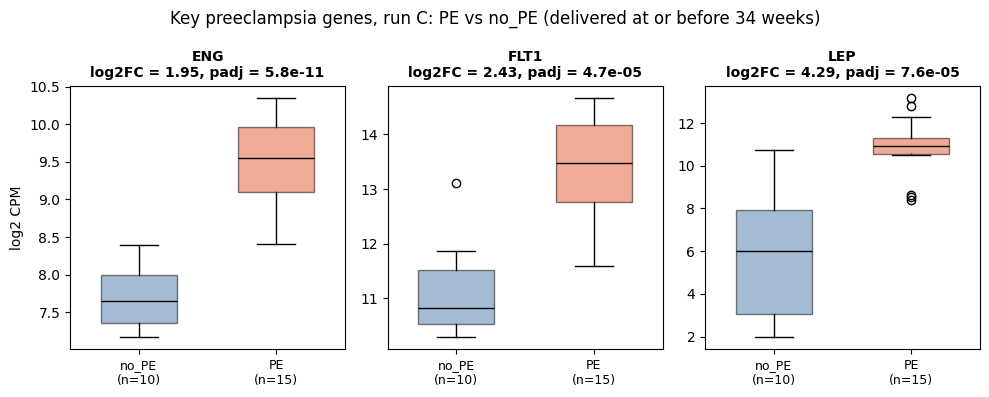

In [ ]:
run = comparisons["C_ga34"]
comp_counts = run["counts"]            # run C's 25 samples
comp_meta = run["metadata"]
res = all_runs["C_ga34"]

genes = ["ENG", "FLT1", "LEP"]

log_cpm = np.log2(comp_counts.div(comp_counts.sum(axis=0), axis=1) * 1e6 + 1)

colors = {"no_PE": "#4C78A8", "PE": "#E4572E"}
fig, axes = plt.subplots(1, 3, figsize=(10, 4), sharex=True)
for ax, g in zip(axes, genes):
    data = [log_cpm.loc[g, comp_meta["pe_status"] == s].values for s in ["no_PE", "PE"]]
    bp = ax.boxplot(data, widths=0.55, patch_artist=True)
    for patch, s in zip(bp["boxes"], ["no_PE", "PE"]):
        patch.set_facecolor(colors[s]); patch.set_alpha(0.5)
    for med in bp["medians"]:
        med.set_color("black")
    lfc, padj = res.loc[g, "log2FoldChange"], res.loc[g, "padj"]
    ax.set_title(f"{g}\nlog2FC = {lfc:.2f}, padj = {padj:.1e}", fontsize=10, fontweight="bold")
    ax.set_xticks([1, 2])
    ax.set_xticklabels([f"no_PE\n(n={len(data[0])})", f"PE\n(n={len(data[1])})"], fontsize=9)
axes[0].set_ylabel("log2 CPM")
fig.suptitle("Key preeclampsia genes, run C: PE vs no_PE (delivered at or before 34 weeks)")
plt.tight_layout()
fig.savefig(RESULTS_DIR / "eng_flt1_lep_boxplot_C.png", dpi=300)
plt.show()

## 6. Read the Results

- `log2FoldChange`: +1 means twice as high in CASE, −1 means half as high
- `padj`: adjusted p-value, smaller means stronger evidence
- `baseMean`: average count, very low values are unreliable

Set your own cutoffs. Try a few values and note how much the number of passing genes changes.


===== A_naive =====
369 genes pass (256 higher in PE, 113 lower)


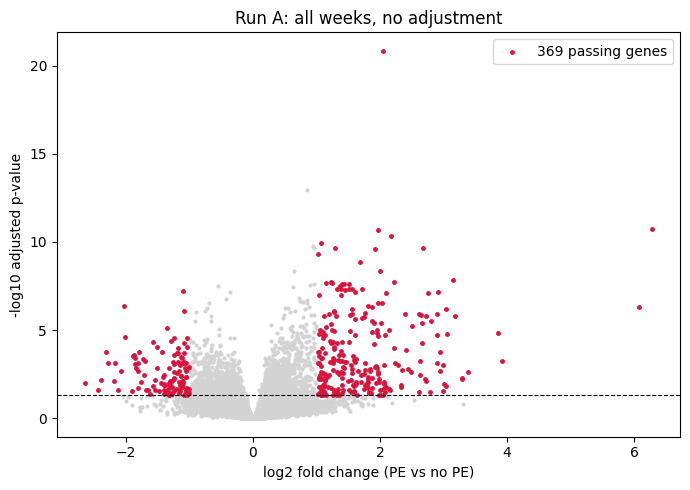


===== B_adjusted =====
273 genes pass (208 higher in PE, 65 lower)


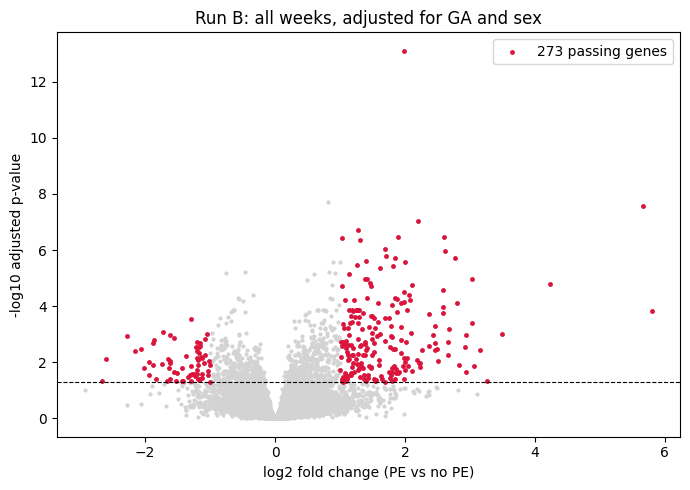


===== C_ga34 =====
188 genes pass (156 higher in PE, 32 lower)


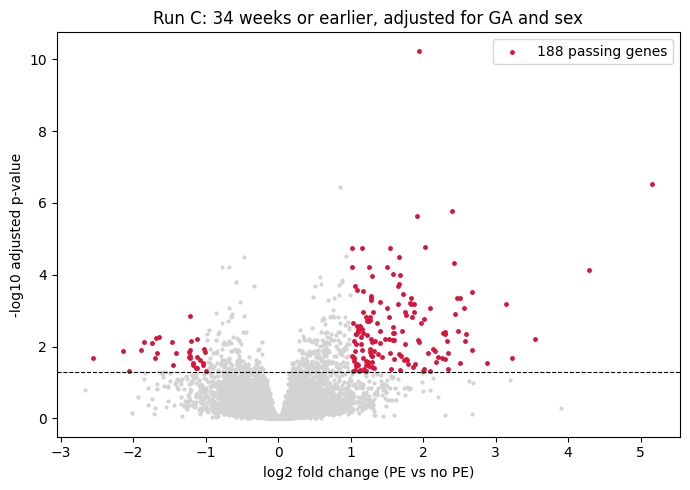

In [ ]:
# STEP 6: VOLCANO PLOTS FOR ALL RUNS

PADJ_CUTOFF = 0.05
LFC_CUTOFF = 1

for name, results in all_runs.items():
    print("\n=====", name, "=====")

    # Identify significant genes
    hits = results[
        (results["padj"] < PADJ_CUTOFF) &
        (results["log2FoldChange"].abs() >= LFC_CUTOFF)
    ]

    print(
        f"{len(hits)} genes pass "
        f"({(hits['log2FoldChange'] > 0).sum()} higher in PE, "
        f"{(hits['log2FoldChange'] < 0).sum()} lower)"
    )

    # Volcano plot for this run
    fig, ax = plt.subplots(figsize=(7, 5))

    ax.scatter(
        results["log2FoldChange"],
        -np.log10(results["padj"].clip(lower=1e-300)),
        s=4,
        color="lightgray"
    )

    ax.scatter(
        hits["log2FoldChange"],
        -np.log10(hits["padj"].clip(lower=1e-300)),
        s=6,
        color="crimson",
        label=f"{len(hits)} passing genes"
    )

    ax.axhline(-np.log10(PADJ_CUTOFF), ls="--", lw=0.8, color="black")
    ax.set_xlabel("log2 fold change (PE vs no PE)")
    ax.set_ylabel("-log10 adjusted p-value")
    ax.set_title(runs[name]["title"])
    ax.legend()

    plt.tight_layout()
    fig.savefig(RESULTS_DIR / f"volcano_{name}.png", dpi=300)
    plt.show()

## 7. Connect Genes to Cell Types

First, check which passing genes are known markers of broad placental cell types. If many markers of one cell type move in the same direction, a change in cell mix is one possible explanation.

Gene identifiers in the counts table may not be gene symbols. If no genes match, check the data dictionary for how to map them.

In [ ]:
markers = pd.read_csv(DATA_DIR / "interpretation" / "track01_marker_matrix.csv")

if hits is not None:
    overlap = markers.merge(hits[["log2FoldChange", "padj"]], left_on="gene_symbol", right_index=True)
    if overlap.empty:
        print("None of your passing genes are in the marker table.")
    else:
        display(overlap.sort_values(["cell_class", "log2FoldChange"]))
else:
    print("Marker table loaded:", markers["cell_class"].nunique(), "cell classes. Set cutoffs in Section 6 to compare.")

,cell_class,compartment,gene_symbol,log2FoldChange,padj
4,syncytiotrophoblast,fetal,CGA,1.043719,0.025921


In [ ]:
res_c = all_runs["C_ga34"]
all_markers = markers.merge(res_c[["baseMean", "log2FoldChange", "padj"]],
                            left_on="gene_symbol", right_index=True, how="left")
all_markers["passes"] = (all_markers["padj"] < PADJ_CUTOFF) & (all_markers["log2FoldChange"].abs() >= LFC_CUTOFF)
all_markers.to_csv(RESULTS_DIR / "marker_genes_runC.csv", index=False)

summary = all_markers.groupby("cell_class").agg(
    median_log2FC=("log2FoldChange", "median"),
    markers_up=("log2FoldChange", lambda x: int((x > 0).sum())),
    markers_down=("log2FoldChange", lambda x: int((x < 0).sum())),
    markers_passing=("passes", "sum"),
).round(2)
summary

,median_log2FC,markers_up,markers_down,markers_passing
cell_class,,,,
decidual_macrophage,-0.17,1,3,0
decidual_nk_cell,0.48,3,1,0
decidual_stromal_cell,-0.21,1,3,0
endothelial_cell,0.23,4,0,0
extravillous_trophoblast,-0.04,1,3,0
perivascular_cell,0.12,2,2,0
syncytiotrophoblast,0.48,3,1,1
t_cell,-0.02,1,2,0
villous_cytotrophoblast,-0.20,1,3,0


Next, look up at least three of your genes in the [Zeisel/Admati gene browser](https://storage.googleapis.com/www_zeisellab/PE_web/pe_web_test_v1.html) (required). Record what you see in the table below; it is saved to `results/browser_lookups.csv` for your submission.

In [ ]:
# You decide: one row per gene you looked up
# browser_lookups = pd.DataFrame([
#     # {"gene": "GENE_A", "cell_types_expressing": "...", "differs_PE_vs_control": "...", "notes": "..."},
# ])
# if not browser_lookups.empty:
#     browser_lookups.to_csv(RESULTS_DIR / "browser_lookups.csv", index=False)
#     display(browser_lookups)
# else:
#     print("Add at least three genes to browser_lookups.")

# Our browser lookups (Zeisel/Admati gene browser)
browser_lookups = pd.DataFrame([
    {"gene": "FLT1",
     "cell_types_expressing": "Trophoblast (mainly extravillous trophoblast, also syncytiotrophoblast); some pericytes and endothelial cells",
     "differs_PE_vs_control": "Browser marks differences in trophoblast cell types",
     "notes": "Consistent with our bulk result (higher in PE in all three runs)"},
    {"gene": "ENG",
     "cell_types_expressing": "Endothelial cells, syncytiotrophoblast, extravillous trophoblast, Hofbauer cells",
     "differs_PE_vs_control": "Browser marks differences in several trophoblast and vascular cell types",
     "notes": "Consistent with bulk result, but used by several cell types so hard to place in one"},
    {"gene": "LEP",
     "cell_types_expressing": "Syncytiotrophoblast almost only",
     "differs_PE_vs_control": "Browser marks a difference in syncytiotrophoblast",
     "notes": "Very cell specific; consistent with bulk result; syncytiotrophoblast markers mostly unchanged, suggesting a behavior change"}
])
if not browser_lookups.empty:
    browser_lookups.to_csv(RESULTS_DIR / "browser_lookups.csv", index=False)
    display(browser_lookups)
else:
    print("Add at least three genes to browser_lookups.")

,gene,cell_types_expressing,differs_PE_vs_control,notes
0,FLT1,"Trophoblast (mainly extravillous trophoblast, ...",Browser marks differences in trophoblast cell ...,Consistent with our bulk result (higher in PE ...
1,ENG,"Endothelial cells, syncytiotrophoblast, extrav...",Browser marks differences in several trophobla...,"Consistent with bulk result, but used by sever..."
2,LEP,Syncytiotrophoblast almost only,Browser marks a difference in syncytiotrophoblast,Very cell specific; consistent with bulk resul...


## 8. Optional: Single-Cell Extension

The pseudobulk files hold counts summed by donor and cell type. To test one cell type, filter both tables to that cell type and rerun Sections 4 to 6 with `counts` and `metadata` replaced by the filtered tables. The data dictionary describes the column layout. Each donor counts once, and the early-onset comparison is exploratory.

In [ ]:
pb_counts = load_table(DATA_DIR / "extension" / "pseudobulk" / "track01_pseudobulk_counts.csv")
pb_metadata = load_table(DATA_DIR / "extension" / "pseudobulk" / "track01_pseudobulk_metadata.csv")
if pb_counts is not None:
    print("Pseudobulk counts:", pb_counts.shape)
    display(pb_metadata.head())

Pseudobulk counts: (33660, 362)


,donor_id,cell_class,compartment,n_cells,total_counts,pe_status,onset_group,clinical_group,early_onset_comparison,fgr_status,...,labor_induction,magnesium_sulfate,anesthesia,ga_delivery_weeks,birthweight_g,birthweight_percentile_dolberg,maternal_age_years,n_libraries,library_ids,qc_flags
pseudobulk_id,,,,,,,,,,,,,,,,,,,,,
PE_early_1__b_cell,PE_early_1,b_cell,immune,19,200845,PE,early,PE_early,exploratory_3_control_vs_10_PE,FGR,...,NaN,yes,spinal,26.400,750,13,32,2,63-1;63-2,fgr_with_birthweight_percentile_ge10
PE_early_10__b_cell,PE_early_10,b_cell,immune,16,168046,PE,early,PE_early,exploratory_3_control_vs_10_PE,no_FGR,...,no,yes,spinal,29.857,1645,73,26,1,119-1,none
PE_early_2__b_cell,PE_early_2,b_cell,immune,16,178170,PE,early,PE_early,exploratory_3_control_vs_10_PE,FGR,...,NaN,yes,general,34.100,1590,7,29,1,86-1,none
PE_early_3__b_cell,PE_early_3,b_cell,immune,11,120252,PE,early,PE_early,exploratory_3_control_vs_10_PE,no_FGR,...,NaN,no,general,35.857,2274,23,35,1,88-1,none
PE_early_4__b_cell,PE_early_4,b_cell,immune,7,76405,PE,early,PE_early,exploratory_3_control_vs_10_PE,no_FGR,...,NaN,yes,spinal,33.143,2845,90,21,1,92-1,none


## Next

Go to [Step 4: Submit](../4-submit.md). Save the figures you want to use, and fill in the hypothesis card.